# 06 Experiments: trying to push F1 above 0.44

**Starting point.** Every model in notebook 05 lands between 0.41 and 0.42 cross-validated F1 (least squares,
ridge, logistic regression, under/oversampling). When very different models agree like that, the limit is
usually the **information in the features**, not the optimizer. Notebook 01 keeps only 45 of the 321 raw columns
and drops whole groups by hand; it says itself that an ablation would be needed to justify that.

| Reference | F1 |
|---|---|
| Ridge, notebook 01 features (nb 05, 5-fold CV) | 0.412 |
| Reg. logistic regression, GD (nb 05, 5-fold CV) | ~0.418 |
| Reg. logistic regression + squares (nb 04, single 80/20 split) | 0.423 |
| Best group on the leaderboard | 0.457 |

**Experiments**, each one compared with the same stratified 5-fold CV and an F1-tuned threshold:

- **A.** Add each excluded feature group back, one at a time (ridge: closed form, seconds per run).
- **B.** Greedy forward selection of groups.
- **C.** Logistic regression trained to convergence with **Newton's method**.
- **D.** Extra features: squares of numeric columns, interactions with age and sex.
- **E.** Ensemble of ridge and logistic regression.
- **F.** Final model trained on all rows and a submission file.

The feature pipeline is in `feature_engineering.py`; with no group added it reproduces notebook 01's matrix
exactly (same 177 columns, differences < 1e-6).

**About one group.** Notebook 01's "post-diagnosis" group is split in two here. `cvd_care` (heart-attack rehab,
aspirin to prevent a heart attack, ...) are questions mostly asked to, or answered differently by, people who
already had a cardiovascular event: a gain from them may be the label leaking in. They are **excluded unless
`ALLOW_CVD_CARE = True`**, and their effect is shown separately so the team can decide.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import feature_engineering as fe
from cross_validation import build_k_indices, cross_validation
from helpers import create_csv_submission
from metrics import best_f1_threshold, compute_metrics, predict_labels

# NumPy 2.0 with Apple's Accelerate BLAS emits spurious matmul warnings on finite data.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1
ALLOW_CVD_CARE = False   # see the introduction

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10,
})

In [2]:
start = time.time()
raw = fe.load_raw(PROJECT_ROOT / "dataset")   # parses the CSVs once, then uses a cache
decoded = fe.decode_missing(raw)
y = raw["y_train"]
k_indices = build_k_indices(y, K_FOLD, seed=SEED)
print(f"raw: {raw['x_train'].shape[1]} columns, {len(y)} train rows ({y.mean():.2%} positive), "
      f"{len(raw['test_ids'])} test rows  ({time.time() - start:.0f}s)")


def features(keep_groups=(), **kwargs):
    # Train / test matrices with the bias column.
    x_tr, x_te, names = fe.build_features(raw, keep_groups=keep_groups, decoded=decoded, **kwargs)
    return np.c_[np.ones(len(x_tr)), x_tr], np.c_[np.ones(len(x_te)), x_te], names


def newton(y, tx, params):
    # Adapter so cross_validation can call the Newton solver.
    return fe.reg_logistic_newton(y, tx, params["lambda_"])[0]


def run(tx, model, params, label=""):
    # 5-fold CV on the shared folds; prints and returns the result.
    start = time.time()
    r = cross_validation(y, tx, model, params, k_indices)
    print(f"{label:<44} D = {tx.shape[1]:>4}   F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
          f"P = {r['precision_mean']:.3f}  R = {r['recall_mean']:.3f}   ({time.time() - start:.0f}s)")
    return r


results = {}   # name -> (cv result, description) for the final summary

raw: 321 columns, 328135 train rows (8.83% positive), 109379 test rows  (8s)


## Baseline

Notebook 01's features (no group added back), ridge with a small λ grid. Every experiment below is
compared with this number, on the same folds.

In [3]:
tx_base, _, _ = features()
for lam in [1e-4, 1e-3, 1e-2]:
    r = run(tx_base, "ridge_regression", {"lambda_": lam}, f"baseline ridge, λ = {lam:g}")
    if "baseline ridge" not in results or r["f1_mean"] > results["baseline ridge"][0]["f1_mean"]:
        results["baseline ridge"] = (r, f"nb 01 features, λ = {lam:g}")
        RIDGE_LAMBDA = lam
BASE_F1 = results["baseline ridge"][0]["f1_mean"]
print(f"ridge λ used from now on: {RIDGE_LAMBDA:g}")

baseline ridge, λ = 0.0001                   D =  178   F1 = 0.4108 ± 0.0070   P = 0.339  R = 0.521   (2s)
baseline ridge, λ = 0.001                    D =  178   F1 = 0.4111 ± 0.0066   P = 0.336  R = 0.531   (2s)
baseline ridge, λ = 0.01                     D =  178   F1 = 0.4120 ± 0.0061   P = 0.335  R = 0.535   (2s)
ridge λ used from now on: 0.01


## A. Add each excluded group back, one at a time

Ridge is closed form, so a full 5-fold run takes seconds: a cheap proxy to rank feature sets before using the
slower logistic regression. A gain smaller than about one fold std (~0.005) should not be trusted on its own.

In [4]:
ablation = {}
for group in fe.OPTIONAL_GROUPS:
    tx, _, _ = features((group,))
    ablation[group] = run(tx, "ridge_regression", {"lambda_": RIDGE_LAMBDA}, f"+ {group}")

all_safe = tuple(g for g in fe.OPTIONAL_GROUPS if g != "cvd_care")
tx, _, _ = features(all_safe)
ablation["all except cvd_care"] = run(tx, "ridge_regression", {"lambda_": RIDGE_LAMBDA}, "+ all except cvd_care")
tx, _, _ = features(tuple(fe.OPTIONAL_GROUPS))
ablation["all groups"] = run(tx, "ridge_regression", {"lambda_": RIDGE_LAMBDA}, "+ all groups")
del tx

+ cvd_care                                   D =  193   F1 = 0.4152 ± 0.0063   P = 0.337  R = 0.541   (3s)
+ risk_management                            D =  194   F1 = 0.4140 ± 0.0056   P = 0.332  R = 0.548   (3s)
+ optional_modules                           D =  578   F1 = 0.4161 ± 0.0062   P = 0.343  R = 0.528   (14s)
+ follow_up                                  D =  299   F1 = 0.4133 ± 0.0054   P = 0.328  R = 0.558   (5s)
+ data_quality                               D =  192   F1 = 0.4120 ± 0.0063   P = 0.335  R = 0.535   (2s)
+ redundant                                  D =  400   F1 = 0.4187 ± 0.0049   P = 0.328  R = 0.577   (7s)
+ all except cvd_care                        D =  951   F1 = 0.4238 ± 0.0057   P = 0.341  R = 0.561   (43s)
+ all groups                                 D =  966   F1 = 0.4261 ± 0.0061   P = 0.353  R = 0.538   (43s)


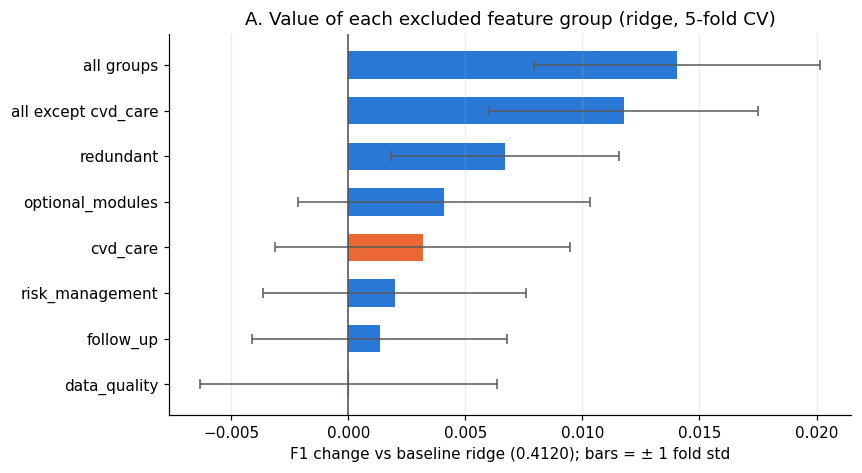

In [5]:
names = list(ablation)
deltas = np.array([ablation[n]["f1_mean"] - BASE_F1 for n in names])
stds = np.array([ablation[n]["f1_std"] for n in names])
order = np.argsort(deltas)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ORANGE if "cvd_care" in names[i] and names[i] != "all except cvd_care" else
          (BLUE if deltas[i] >= 0 else "0.6") for i in order]
ax.barh([names[i] for i in order], deltas[order], xerr=stds[order], color=colors, height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
ax.axvline(0, color="0.3", linewidth=1)
ax.set_xlabel(f"F1 change vs baseline ridge ({BASE_F1:.4f}); bars = ± 1 fold std")
ax.set_title("A. Value of each excluded feature group (ridge, 5-fold CV)")
ax.grid(axis="y", visible=False)
plt.show()

## B. Greedy forward selection of groups

Start from the baseline and repeatedly add the group that improves CV F1 the most; stop when no group adds
more than 0.001. `cvd_care` is only a candidate if `ALLOW_CVD_CARE` is set.

In [ ]:
candidates = [g for g in fe.OPTIONAL_GROUPS if ALLOW_CVD_CARE or g != "cvd_care"]
chosen, best_f1 = [], BASE_F1
while candidates:
    trial = {}
    for g in candidates:
        tx, _, _ = features(tuple(chosen + [g]))
        trial[g] = cross_validation(y, tx, "ridge_regression", {"lambda_": RIDGE_LAMBDA}, k_indices)
    g_best = max(trial, key=lambda g: trial[g]["f1_mean"])
    gain = trial[g_best]["f1_mean"] - best_f1
    print(f"step {len(chosen) + 1}: best addition = {g_best:<18} F1 = {trial[g_best]['f1_mean']:.4f} "
          f"(gain {gain:+.4f})")
    if gain < 0.001:
        break
    chosen.append(g_best)
    candidates.remove(g_best)
    best_f1 = trial[g_best]["f1_mean"]
    results["ridge, selected groups"] = (trial[g_best], "+ " + ", ".join(chosen))
del tx

GROUPS = tuple(chosen)
print(f"\nselected groups: {GROUPS}  ->  ridge F1 = {best_f1:.4f} (baseline {BASE_F1:.4f})")

## C. Logistic regression trained to convergence (Newton's method)

The features are badly conditioned (condition number ~10⁶ in notebook 05), so gradient descent stops far from the
optimum after a few hundred steps. Newton's method uses the Hessian `X^T S X / N + 2λI` and converges in about
ten steps, with no step size to tune: it minimizes **exactly the same objective** as `reg_logistic_regression`.
With a few hundred features the Hessian is cheap to form.

In [ ]:
tx_sel, _, _ = features(GROUPS)

# Convergence check on all training rows: Newton vs the course GD implementation.
import implementations as impl
lam = 1e-4
w_newton, n_steps = fe.reg_logistic_newton(y, tx_sel, lam)
obj = lambda w: np.mean(np.logaddexp(0, tx_sel @ w) - y * (tx_sel @ w)) + lam * w @ w
w_gd, _ = impl.reg_logistic_regression(y, tx_sel, lam, np.zeros(tx_sel.shape[1]), 500, 0.1)
print(f"objective after Newton ({n_steps} steps): {obj(w_newton):.6f}")
print(f"objective after GD (500 steps, γ = 0.1):  {obj(w_gd):.6f}")

for lam in [1e-6, 1e-5, 1e-4, 1e-3]:
    r = run(tx_sel, newton, {"lambda_": lam}, f"Newton logistic, λ = {lam:g}")
    if "logistic (Newton)" not in results or r["f1_mean"] > results["logistic (Newton)"][0]["f1_mean"]:
        results["logistic (Newton)"] = (r, f"selected groups, λ = {lam:g}")
        LOGREG_LAMBDA = lam
print(f"best λ = {LOGREG_LAMBDA:g}")

## D. Extra features: non-linear terms

Two cheap ways to let a linear model bend:

- **squares** of the numeric columns only (notebook 04 squares every column, but for 0/1 one-hot columns
  x² = x, so most of those columns are exact duplicates);
- **interactions** with age (`_AGE80`) and sex (`SEX=2`): every column multiplied by age / by sex, so each risk
  factor can weigh differently for older people or for women.

In [ ]:
variants = {
    "squares": dict(square_numeric=True),
    "squares + age interactions": dict(square_numeric=True, interact_with=("_AGE80",)),
    "squares + age & sex interactions": dict(square_numeric=True, interact_with=("_AGE80", "SEX=2")),
}
extra = {}
for name, kwargs in variants.items():
    tx, _, _ = features(GROUPS, **kwargs)
    extra[name] = (run(tx, newton, {"lambda_": LOGREG_LAMBDA}, f"Newton logistic + {name}"), kwargs)
    del tx

best_extra = max(extra, key=lambda n: extra[n][0]["f1_mean"])
if extra[best_extra][0]["f1_mean"] > results["logistic (Newton)"][0]["f1_mean"]:
    results[f"logistic (Newton) + {best_extra}"] = (extra[best_extra][0], f"λ = {LOGREG_LAMBDA:g}")
    EXTRA = extra[best_extra][1]
else:
    EXTRA = {}
print(f"\nkept extra features: {EXTRA or 'none'}")

Interactions add many columns, so the regularization strength may need to change. A quick λ check on the kept variant:

In [ ]:
tx_final, tx_test_final, final_names = features(GROUPS, **EXTRA)
best_name = max((n for n in results if n.startswith("logistic")), key=lambda n: results[n][0]["f1_mean"])
for lam in [LOGREG_LAMBDA * 10, LOGREG_LAMBDA / 10]:
    r = run(tx_final, newton, {"lambda_": lam}, f"final features, λ = {lam:g}")
    if r["f1_mean"] > results[best_name][0]["f1_mean"]:
        results[best_name] = (r, f"λ = {lam:g}")
        LOGREG_LAMBDA = lam
print(f"final logistic model: {best_name}, λ = {LOGREG_LAMBDA:g}, D = {tx_final.shape[1]}")

## E. Ensemble: ridge + logistic regression

The two models make different errors. We average their out-of-fold scores after standardizing each one
(mean 0, std 1), and tune one threshold on the average.

In [ ]:
logreg_cv = results[best_name][0]
ridge_cv = cross_validation(y, tx_final, "ridge_regression", {"lambda_": RIDGE_LAMBDA}, k_indices)


def standardize(scores, ref):
    return (scores - ref.mean()) / ref.std()


def ensemble_cv(weight):
    # CV metrics of weight * logistic + (1 - weight) * ridge (standardized OOF scores).
    s = (weight * standardize(logreg_cv["oof_scores"], logreg_cv["oof_scores"])
         + (1 - weight) * standardize(ridge_cv["oof_scores"], ridge_cv["oof_scores"]))
    thr, _ = best_f1_threshold(y, s)
    folds = [compute_metrics(y[idx], predict_labels(s[idx], thr)) for idx in k_indices]
    f1 = [m["f1"] for m in folds]
    return {"threshold": thr, "f1_mean": float(np.mean(f1)), "f1_std": float(np.std(f1)),
            "precision_mean": float(np.mean([m["precision"] for m in folds])),
            "recall_mean": float(np.mean([m["recall"] for m in folds])),
            "accuracy_mean": float(np.mean([m["accuracy"] for m in folds])), "oof_scores": s}


weights = np.linspace(0, 1, 11)
ens = [ensemble_cv(a) for a in weights]
ENS_WEIGHT = float(weights[np.argmax([e["f1_mean"] for e in ens])])
results["ensemble"] = (ensemble_cv(ENS_WEIGHT), f"{ENS_WEIGHT:.1f} × logistic + {1 - ENS_WEIGHT:.1f} × ridge")

fig, ax = plt.subplots()
ax.plot(weights, [e["f1_mean"] for e in ens], color=BLUE, marker="o", markersize=4)
ax.set_xlabel("weight of logistic regression (0 = ridge only, 1 = logistic only)")
ax.set_ylabel("cross-validated F1")
ax.set_title("E. Ridge + logistic ensemble")
plt.show()
print(f"best weight = {ENS_WEIGHT:.1f}: F1 = {results['ensemble'][0]['f1_mean']:.4f}")

## Summary

All rows use the same 5 stratified folds. Note that the threshold is tuned on the same out-of-fold scores it is
evaluated on, so all numbers are slightly optimistic, by the same small amount for every row.

In [ ]:
rows = sorted(results.items(), key=lambda kv: kv[1][0]["f1_mean"], reverse=True)
print(f"{'model':<46} {'F1':>15} {'precision':>9} {'recall':>6}  details")
for name, (r, desc) in rows:
    print(f"{name:<46} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['precision_mean']:>9.4f} "
          f"{r['recall_mean']:>6.4f}  {desc}")

labels = [n for n, _ in rows][::-1]
means = np.array([r["f1_mean"] for _, (r, _) in rows])[::-1]
stds = np.array([r["f1_std"] for _, (r, _) in rows])[::-1]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(rows) + 1.5))
ax.barh(labels, means, xerr=stds, color=BLUE, height=0.6, error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, v in enumerate(means):
    ax.text(v + stds[i] + 0.002, i, f"{v:.3f}", va="center", color="0.25")
ax.axvline(0.457, color=ORANGE, linestyle="--", linewidth=1.5)
ax.annotate("leaderboard best (0.457)", (0.457, len(rows) - 0.5), xytext=(4, 0), textcoords="offset points",
            color=ORANGE, va="center")
ax.set_xlim(means.min() - 0.02, max(0.465, means.max() + 0.02))
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Experiments summary")
ax.grid(axis="y", visible=False)
plt.show()

## F. Final model and submission

The best row of the summary is retrained on **all** training rows and applied to the test set, with the threshold
chosen on the out-of-fold scores. The file is written to `submission_experiments.csv` (git-ignored); upload it to
AIcrowd to get the real test F1.

In [ ]:
best = rows[0][0]
print(f"final model: {best}")

w_logreg = fe.reg_logistic_newton(y, tx_final, LOGREG_LAMBDA)[0]
w_ridge, _ = impl.ridge_regression(y, tx_final, RIDGE_LAMBDA)

if best == "ensemble":
    s_test = (ENS_WEIGHT * standardize(tx_test_final @ w_logreg, logreg_cv["oof_scores"])
              + (1 - ENS_WEIGHT) * standardize(tx_test_final @ w_ridge, ridge_cv["oof_scores"]))
    threshold = results["ensemble"][0]["threshold"]
elif best.startswith("logistic"):
    s_test, threshold = tx_test_final @ w_logreg, results[best][0]["threshold"]
else:
    s_test, threshold = tx_test_final @ w_ridge, ridge_cv["threshold"]

test_predictions = np.where(s_test >= threshold, 1, -1)
oof_rate = np.mean(results[best][0]["oof_scores"] >= threshold) if "oof_scores" in results[best][0] else float("nan")
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_experiments.csv"
create_csv_submission(raw["test_ids"], test_predictions, submission_path)
print(f"submission written to {submission_path}")

## Conclusions

CONCLUSIONS_PLACEHOLDER